# Introduction (TBD)

# Libraries and Global Variables

In [81]:
#Data Analysis and manupalation libraries
import pandas as pd
import numpy as np
from ydata_profiling import ProfileReport
from pathlib import Path

#Sklearn
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from scipy import stats
#Seaborn
import seaborn as sns

#Matplotlib
import matplotlib.pyplot as plt

In [82]:
#Seed for ML Algorithms
SEED = 81

#Paths
PROJECT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()
)
GENERATED_REPORTS = (PROJECT / "reports" / "generated")

DIABETES_CSV = PROJECT / "data" / "raw" / "diabetic_data.csv"
IDS_MAPING_CSV = PROJECT / "data" / "raw" / "IDS_mapping.csv"


## Diabetes fact table

In [83]:
#Read diabetes CSV
df_diabetes = pd.read_csv(DIABETES_CSV, delimiter=',')
df_diabetes.dtypes.to_csv(PROJECT / "data" / "raw" / "diabetes_dtypes.csv")

#CATEGORIZE VARIABLES

## NUMERIC
NUMERIC = [
    "encounter_id",
    "patient_nbr",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

CATEGORICAL = [
    "race",
    "gender",
    "age",
    "weight",
    "payer_code",
    "medical_specialty",
    "diag_1",
    "diag_2",
    "diag_3",
    "max_glu_serum",
    "A1Cresult",
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "examide",
    "citoglipton",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone",
    "change",
    "diabetesMed",
    "readmitted"
]

In [84]:
df_diabetes.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## IDS Mapping dim tables
TODO: Add small explanation behind logic of generator 

In [85]:
def process_ids_tables():
    #Read IDS mapping CSV
    df_ids_map = pd.read_csv(IDS_MAPING_CSV, header=None, names=range(2), delimiter=',')

    #Define table names
    table_names = ['admission_type', 'discharge_disposition_id', 'admission_source_id']

    groups = df_ids_map[0].isin(table_names).cumsum()

    tables = {g.iloc[0,0]: g.iloc[0:-1] for k,g in df_ids_map.groupby(groups)}

    for name, table in tables.items():
        #Create dataframe
        df = pd.DataFrame(table)

        #Promote first line to header
        df.columns = df.iloc[0]
        df = df.iloc[1:].reset_index(drop=True)

        yield df

ids_mapping_dataframes = process_ids_tables()

#Use generator to create our dataframes for each table

#Admission Types
df_admission_type = next(ids_mapping_dataframes)

#Cast admission_type_id to int for consistency with df_diabetes
df_admission_type['admission_type_id'] = df_admission_type['admission_type_id'].astype(int)

#Discharge Disposition
df_discharge_disposition = next(ids_mapping_dataframes)

#Cast discharge_disposition_id to int for consistency with df_diabetes
df_discharge_disposition['discharge_disposition_id'] = df_discharge_disposition['discharge_disposition_id'].astype(int)

#Admission Source
df_admission_source = next(ids_mapping_dataframes)

#Cast admission_source_id to int for consistency with df_diabetes
df_admission_source['admission_source_id'] = df_admission_source['admission_source_id'].astype(int)

### Admission Type mapping

In [86]:
print(f"Min Id: {df_admission_type['admission_type_id'].min()}")
print(f"Max Id: {df_admission_type['admission_type_id'].max()}")

n_rows = df_admission_type.shape[0]
df_admission_type[:n_rows]

Min Id: 1
Max Id: 8


,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
5,6,NaN
6,7,Trauma Center
7,8,Not Mapped


### Discharge Disposition mapping

In [87]:
print(f"Min Id: {df_discharge_disposition['discharge_disposition_id'].min()}")
print(f"Max Id: {df_discharge_disposition['discharge_disposition_id'].max()}")

n_rows = df_discharge_disposition.shape[0]
df_discharge_disposition[:n_rows]

Min Id: 1
Max Id: 30


10,discharge_disposition_id,description
0,1,Discharged to home
1,2,Discharged/transferred to another short term h...
2,3,Discharged/transferred to SNF
3,4,Discharged/transferred to ICF
4,5,Discharged/transferred to another type of inpa...
5,6,Discharged/transferred to home with home healt...
6,7,Left AMA
7,8,Discharged/transferred to home under care of H...
8,9,Admitted as an inpatient to this hospital
9,10,Neonate discharged to another hospital for neo...


### Admission Source mapping

In [88]:
print(f"Min Id: {df_admission_source['admission_source_id'].min()}")
print(f"Max Id: {df_admission_source['admission_source_id'].max()}")

n_rows = df_admission_source.shape[0]
df_admission_source[:n_rows]

Min Id: 1
Max Id: 25


42,admission_source_id,description
0,1,Physician Referral
1,2,Clinic Referral
2,3,HMO Referral
3,4,Transfer from a hospital
4,5,Transfer from a Skilled Nursing Facility (SNF)
5,6,Transfer from another health care facility
6,7,Emergency Room
7,8,Court/Law Enforcement
8,9,Not Available
9,10,Transfer from critial access hospital


# EDA

Just for starters, we'll create a Profile Report for the diabetes main fact table

In [89]:
def create_profile_report(df, title, file_name):

    profile = ProfileReport(
        df, title = title
    )
    profile.config.html.inline = True

    path_to_html = Path(PROJECT / "reports" / "generated" / file_name)

    if not path_to_html.exists():
        profile.to_file(GENERATED_REPORTS / file_name)

#Create profile report for this dataframe
create_profile_report(df_diabetes, "Diabetes Data Profile Report", "profile-report-diabetes.html")

## Administrative Data
Here we'll explore data regarding administrative data of the patient. This includes the following columns:
- admission_type_id
- admission_source_id
- discharge_disposition_id
- payer_code
- medical_specialty


### Preview, describe, nulls

In [90]:
#Create a list with columns of administrative data
admin_data_cols = [
    "admission_type_id",
    "admission_source_id",
    "discharge_disposition_id",
    "payer_code",
    "medical_specialty"
]

#Create a daframe with only these columns
df_admin_data = df_diabetes[admin_data_cols].copy()

#check dtypes
print(df_admin_data.dtypes)

df_admin_data.tail(10)

admission_type_id            int64
admission_source_id          int64
discharge_disposition_id     int64
payer_code                  object
medical_specialty           object
dtype: object


,admission_type_id,admission_source_id,discharge_disposition_id,payer_code,medical_specialty
101756,1,7,1,MD,?
101757,1,7,1,?,?
101758,1,7,1,MC,?
101759,1,7,1,MC,?
101760,1,7,1,DM,?
101761,1,7,3,MC,?
101762,1,5,4,MC,?
101763,1,7,1,MC,?
101764,2,7,3,MC,Surgery-General
101765,1,7,1,?,?


In [91]:
#Create profile report for this dataframe
create_profile_report(df_admin_data, "Diabetes - Administrative Data Profile Report", "profile-report-admin-data.html")        

In [92]:
#Describe numerical columns
df_admin_data.describe()

,admission_type_id,admission_source_id,discharge_disposition_id
count,101766.000000,101766.000000,101766.000000
mean,2.024006,5.754437,3.715642
std,1.445403,4.064081,5.280166
min,1.000000,1.000000,1.000000
25%,1.000000,1.000000,1.000000
50%,1.000000,7.000000,1.000000
75%,3.000000,7.000000,4.000000
max,8.000000,25.000000,28.000000


**Note to self:** Last id 29 for discharge disposition seems like it's not being used

In [93]:
#Describe categorical columns
df_admin_data.describe(include='object')

,payer_code,medical_specialty
count,101766,101766
unique,18,73
top,?,?
freq,40256,49949


In [94]:
#Percentage of nan values across dataframe
round(df_admin_data.replace('?', np.nan).isna().sum() / df_admin_data.shape[0] * 100, 2)

admission_type_id            0.00
admission_source_id          0.00
discharge_disposition_id     0.00
payer_code                  39.56
medical_specialty           49.08
dtype: float64

**Key Takeaway:** Columns payer_code and medical_specialty have high null values. 39% and 49% respectively

In [95]:
#Check distinct values of payer code for context
pd.DataFrame(df_admin_data['payer_code'].unique())

,0
0,?
1,MC
2,MD
3,HM
4,UN
5,BC
6,SP
7,CP
8,SI
9,DM


Not much to conclude from these values. Looks like country codes but verifying some of them like "OG" they do not correspond to any country.
There is no DIM table for these column. Just keep values as is (mentioned in project guide) and later decide what to do with null values. 

### Distribution

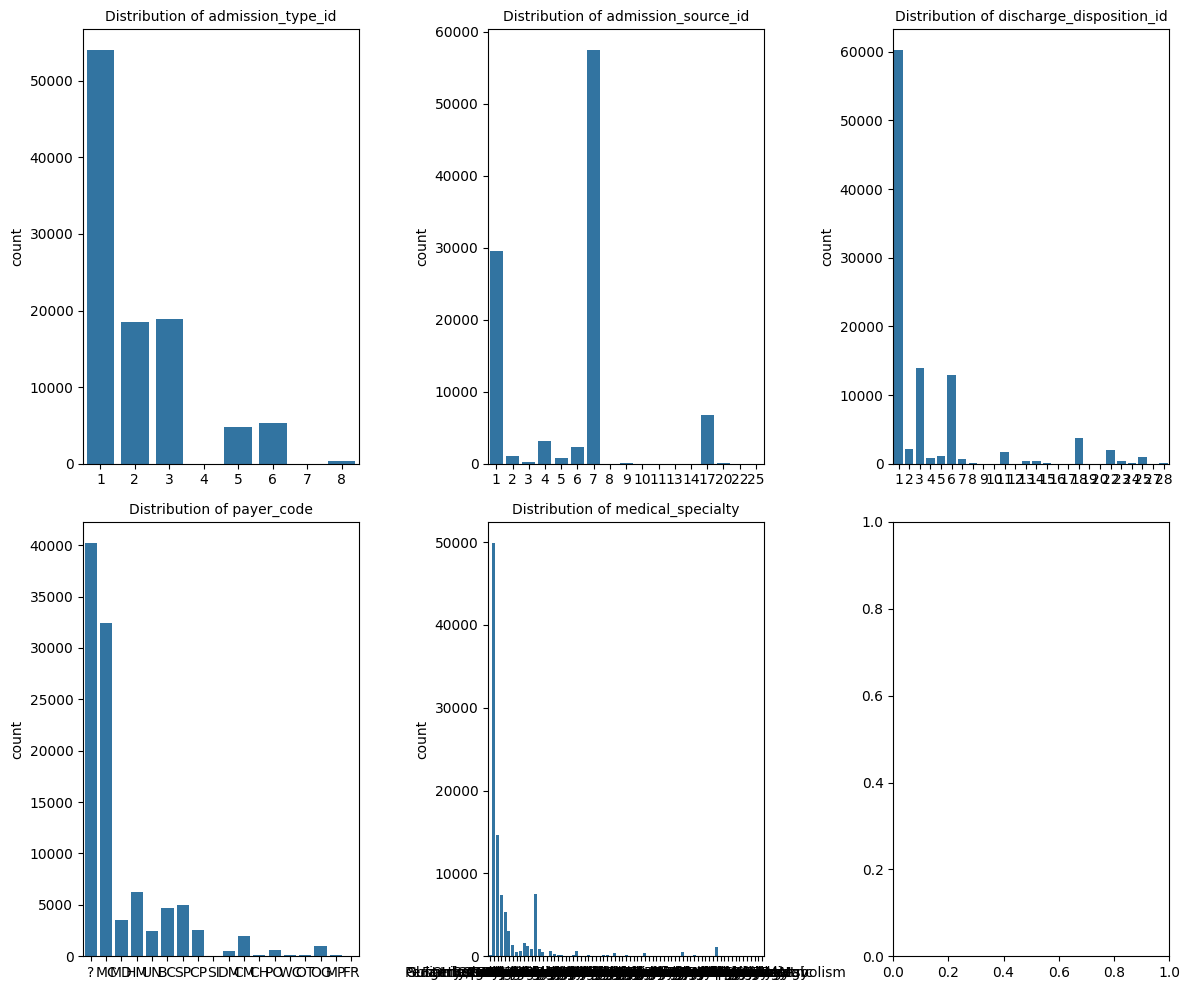

In [ ]:
#Plot distribution in bar charts
fig, axes = plt.subplots(2, 3, figsize=(12, 10))

for ax, col in zip(axes.flatten(), df_admin_data.columns):
    sns.countplot(df_admin_data, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}", fontsize=10)
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

Note: Check why the first value of these columns is almost always the value that occurs more frequently

Looking at the dimension tables displayed above we see:
- Admission Type: 1 -> Emergency
- Admission Source: 7 -> Emergency Room
- Discharge Disposition: 1 -> Discharge to home
- Payer code: ? -> Null
- Medical Specialty: ? -> Null


### Correlation

In [ ]:
#This dataset has int and string values, so I'll encode the str values to int for an improved correlation

df_admin_data_encod = df_admin_data.copy()
#Columns: payer_code, medical_specialty
le = LabelEncoder()
df_admin_data_encod['payer_code'] = le.fit_transform(df_admin_data_encod['payer_code'])
df_admin_data_encod['medical_specialty'] = le.fit_transform(df_admin_data_encod['medical_specialty'])

print(df_admin_data_encod.dtypes)

df_admin_data_encod[['payer_code', 'medical_specialty']].tail(10)

admission_type_id           int64
admission_source_id         int64
discharge_disposition_id    int64
payer_code                  int64
medical_specialty           int64
dtype: object


,payer_code,medical_specialty
101756,9,0
101757,0,0
101758,8,0
101759,8,0
101760,5,0
101761,8,0
101762,8,0
101763,8,0
101764,8,63
101765,0,0


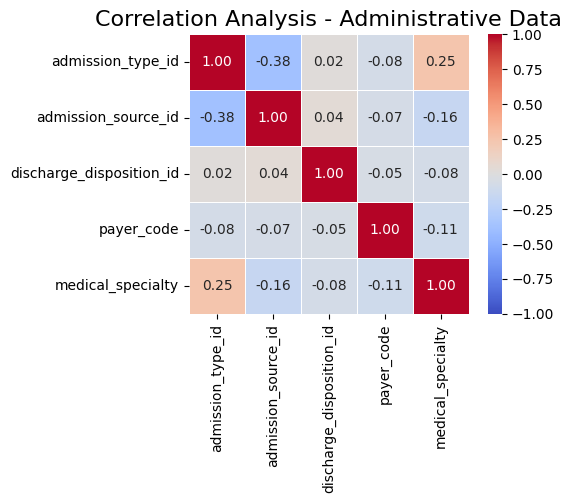

In [ ]:
# Build correlation matrix
# matrix = df_admin_data_encod.corr()

# Build plot
plt.figure(figsize=(6, 5))

#Scale values using min-max scaling to improve correlation visualization
scaler = MinMaxScaler()
df_corr_analysis = pd.DataFrame(
    scaler.fit_transform(df_admin_data_encod),
    columns=df_admin_data_encod.columns,
    index=df_admin_data_encod.index,
)

# Plot heatmap using spearman correlation
sns.heatmap(
    df_admin_data_encod.corr("spearman"),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    linewidth=0.5,
    vmin=-1,
    vmax=1,
)

plt.title("Correlation Analysis - Administrative Data", fontsize=16)
plt.tight_layout()
plt.show()

Let's check for correlation between columns that have similar meaning using qui-square:  
- admission_type_id <-> admission_source_id


## Utilization history/current stay data

### Preview, describe, nulls

In [18]:
util_stay_cols = [
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

df_util_stay_data = df_diabetes[util_stay_cols].copy()

#dtypes
print(df_util_stay_data.dtypes)

df_util_stay_data.head(10)

num_lab_procedures    int64
num_procedures        int64
num_medications       int64
number_outpatient     int64
number_emergency      int64
number_inpatient      int64
dtype: object


,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
0,41,0,1,0,0,0
1,59,0,18,0,0,0
2,11,5,13,2,0,1
3,44,1,16,0,0,0
4,51,0,8,0,0,0
5,31,6,16,0,0,0
6,70,1,21,0,0,0
7,73,0,12,0,0,0
8,68,2,28,0,0,0
9,33,3,18,0,0,0


In [19]:
#Describe
df_util_stay_data.describe()

,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566
std,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000
50%,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000
75%,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000
max,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000


### Distribution
Check distribution of these numerical variables. The skewness of the distribution is important to determine what method of correlation should be used in the next step

In [20]:
df_util_stay_data.columns

Index(['num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient'],
      dtype='object')

num_lab_procedures: 	Mean Val: 43.09564098028811 	Standard Deviation: 19.67426558419223 	IQR Val: 26.0
num_procedures: 	Mean Val: 1.339730361810428 	Standard Deviation: 1.7057985980745933 	IQR Val: 2.0
num_medications: 	Mean Val: 16.021844230882614 	Standard Deviation: 8.127526276448226 	IQR Val: 10.0
number_outpatient: 	Mean Val: 0.36935715268360747 	Standard Deviation: 1.2672588701495553 	IQR Val: 0.0
number_emergency: 	Mean Val: 0.19783621248747127 	Standard Deviation: 0.9304676967848132 	IQR Val: 0.0
number_inpatient: 	Mean Val: 0.635565906098304 	Standard Deviation: 1.2628570853413514 	IQR Val: 1.0


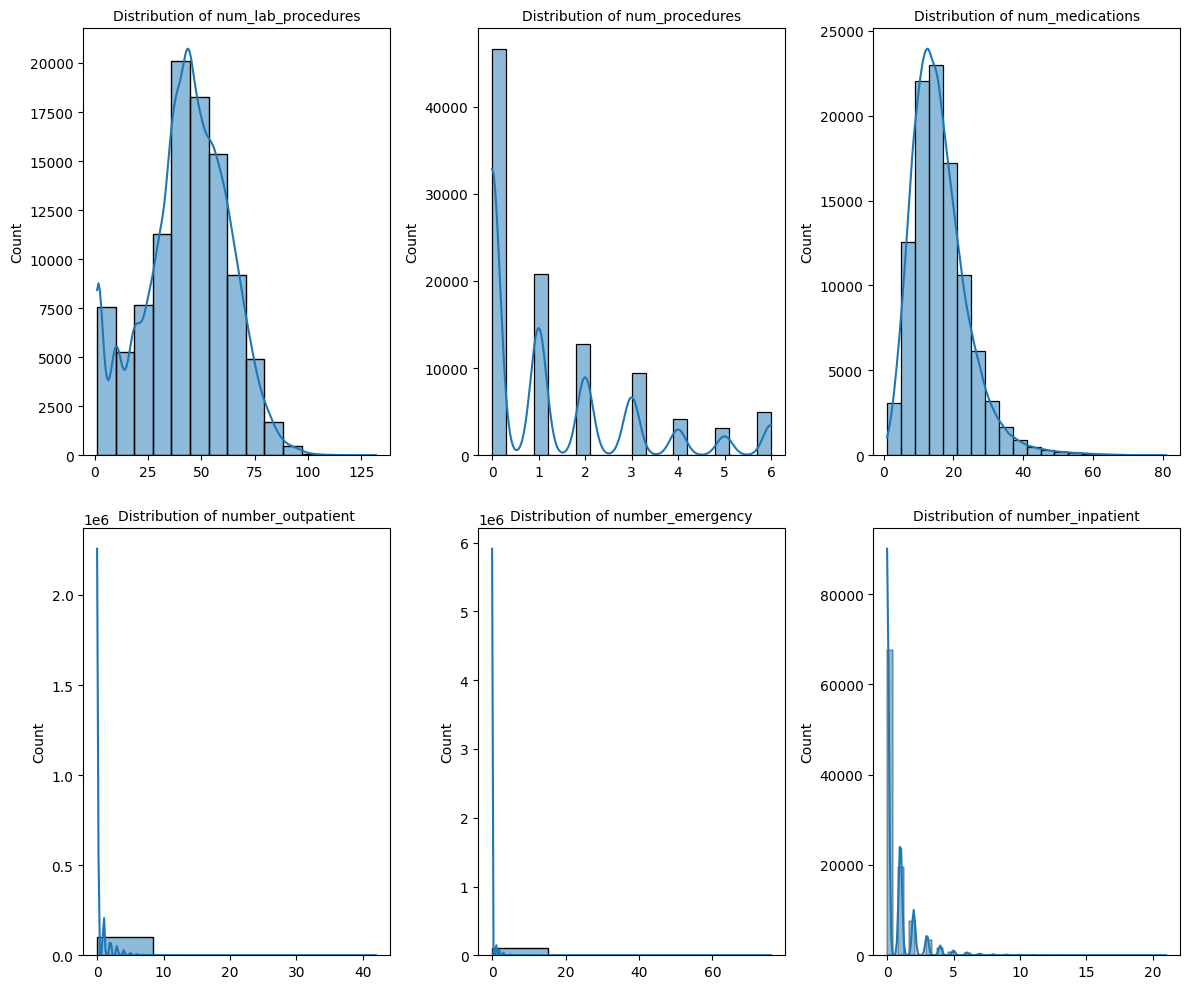

In [47]:
#Statistics of data
for col in df_util_stay_data.columns:
    data = df_util_stay_data[col]

    mean_val = np.mean(data)
    std_val = np.std(data)
    iqr_val = stats.iqr(data)

    print(f"{col}: \tMean Val: {mean_val} \tStandard Deviation: {std_val} \tIQR Val: {iqr_val}")

#Plot distribution in bar charts
fig, axes = plt.subplots(2, 3, figsize=(12, 10))

#Create bins dict
bins_dict = {
    "num_lab_procedures": 15,
    "num_procedures": 20,
    "num_medications": 20,
    "number_outpatient": 5,
    "number_emergency": 5,
    "number_inpatient": 50
}

for ax, col in zip(axes.flatten(), df_util_stay_data.columns):
    sns.histplot(df_util_stay_data, x=col, ax=ax, bins=bins_dict[col], kde=True)
    ax.set_title(f"Distribution of {col}", fontsize=10)
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

**Conclusion:** Looking at the distribution plots (TBD)

Let's plot the distribution of number_outpatient, number_emergency and number_inpatient in plots more tightly adjusted to better view the distributions, although they are most certainly right skewed

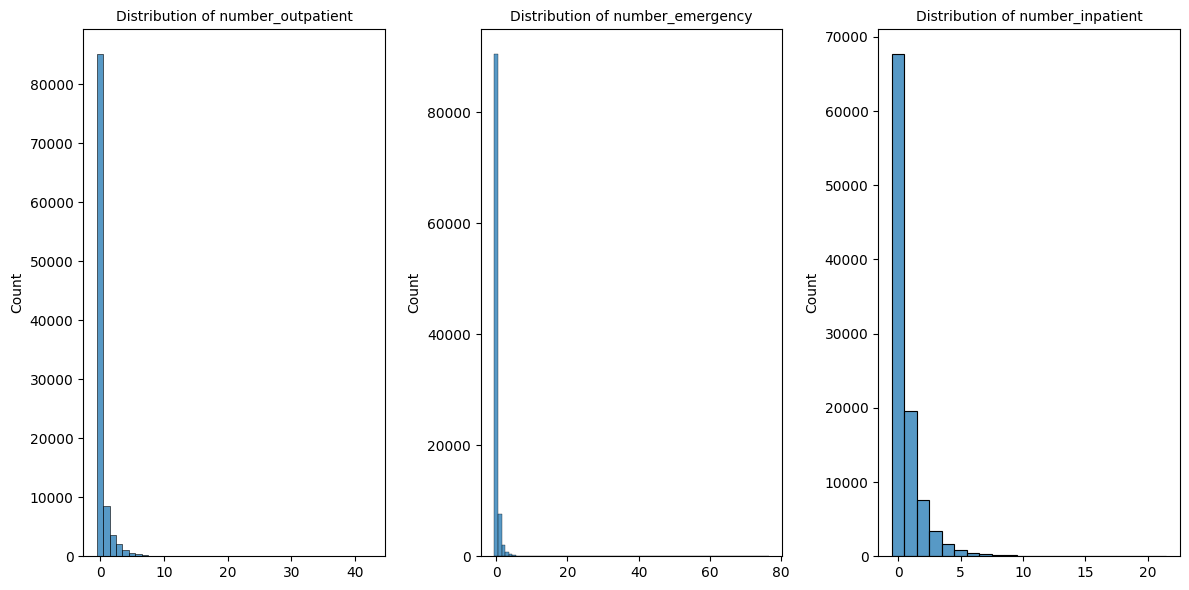

In [53]:
#Plot distribution in bar charts
fig, ax = plt.subplots(1, 3, figsize=(12, 6))
cols = ["number_outpatient", "number_emergency", "number_inpatient"]

for ax, col in zip(ax, cols):
    sns.histplot(df_util_stay_data, x=col, discrete=True, kde=False, ax=ax)
    ax.set_title(f"Distribution of {col}", fontsize=10)
    ax.set_xlabel('')

plt.tight_layout()
plt.show()

**Conclusion** We can definitely conclude that all three variables are highly right skewed and presenting a high likelihood of having outliers. This also verifiable by the values of UIQR presented above where the difference between the first and thrid quartiles are very slim, which tells us the values are concentraded around the mean

### Correlation (with outliers)

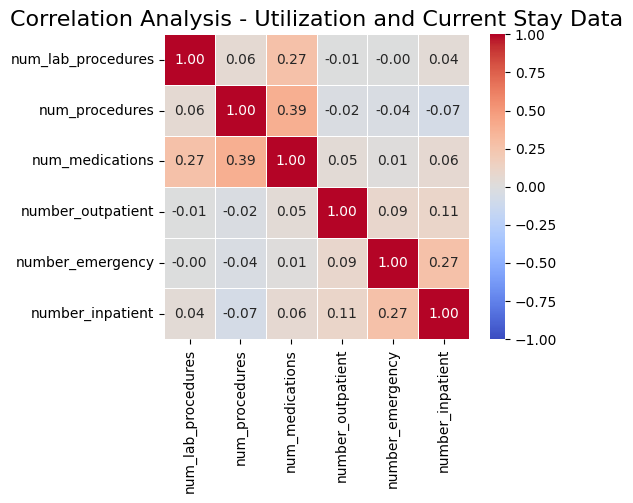

In [61]:
# Build correlation matrix
# matrix = df_util_stay_da.corr()

# Build plot
plt.figure(figsize=(6, 5))

#Scale values using min-max scaling to improve correlation visualization
scaler = MinMaxScaler()
df_corr_analysis = pd.DataFrame(
    scaler.fit_transform(df_util_stay_data),
    columns=df_util_stay_data.columns,
    index=df_util_stay_data.index,
)

# Plot heatmap using spearman correlation
sns.heatmap(
    df_corr_analysis.corr(method='pearson'),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    linewidth=0.5,
    vmin=-1,
    vmax=1,
)

plt.title("Correlation Analysis - Utilization and Current Stay Data", fontsize=16)
plt.tight_layout()
plt.show()

### Correlation (without outliers)
Remove outliers from dataframe and quickly check if correlation is more relevant

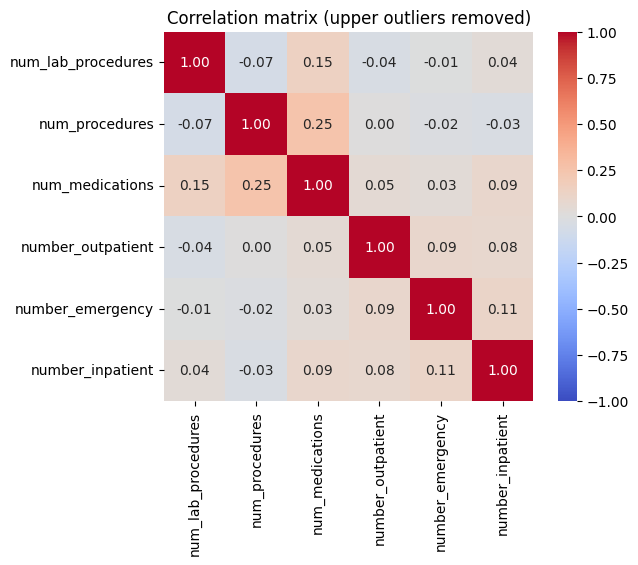

In [67]:
#Upper trimm data in order to remove outliers
df_util_outliers = df_util_stay_data.copy()

cutoffs = {}

for c in df_util_outliers.columns:
    q1, q3 = df_util_outliers[c].quantile([0.25, 0.75])
    cutoffs[c] = df_util_outliers[c].quantile(0.90)

mask = pd.concat([df_util_outliers[c] <= cutoffs[c] for c in df_util_outliers.columns], axis=1).all(axis=1)
clean = df_util_outliers.loc[mask, df_util_outliers.columns]

corr = clean.corr(method = 'spearman')
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (upper outliers removed)")
plt.show()

**Conclusion:** Very similar correlation heatmap compared to the one with outliers, being the only difference where the correlation of medications and lab procedures dropped by about in half

Ultimately, we can conclude that these columns aren't very correlated or similar in anyway. Where we can conclude that there is some correlation is regarding the number of medications, where the higher the lab procedures or normal procedures are, the higher the number of medication is prescribed, which makes total sense.